# Exploratory Data Analysis: CRMLS Single-Family Closed Sales

**Project goal:** Build an automated valuation model (AVM) that predicts `ClosePrice` for a single-family home *before it is listed*.

**Data:** CRMLS closed sales, monthly exports concatenated into one file. CloseDate range: 28 months. Rows/columns (raw): 615,707 rows x 84 columns.

**Scope:** `PropertyType == "Residential"` and `PropertySubType == "SingleFamilyResidence"` (per task doc).

**This notebook:** Explores the data and documents issues. It does **not** clean anything except the scope filter. Cleaning decisions are tagged **Preprocessing** throughout and collected in Part 4 for `02_preprocessing.ipynb`.

**Input:** `data/intermediate/CRMLSSoldCombined.csv`  **Output:** `data/intermediate/CRMLSSoldFiltered.parquet`

> `data/` is added to gitignore so only analysis is pushed, not raw CRMLS data.

# Part 1: Get the right data
Checking if the data contains the right population.

## 1.1 Setup

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid")


def _money(x, pos):
    if abs(x) >= 1e6:
        return f"${x / 1e6:.1f}M"
    return f"${x / 1e3:.0f}K"


money_fmt = mticker.FuncFormatter(_money)

## 1.2 Load raw data
Only run once. Everything after this works from `df_raw` or `df` in memory.

In [4]:
DATA_PATH = "../data/intermediate/CRMLSSoldCombined.csv"
df_raw = pd.read_csv(DATA_PATH, low_memory=False, index_col = 0)
df_raw["CloseDate"] = pd.to_datetime(df_raw["CloseDate"])
df_raw.shape

(615707, 84)

## 1.3 First look
Contains agent names/emails. This is fine locally but shouldn't be used in any final model or dashboard.

In [5]:
df_raw.head()

,Flooring,ViewYN,WaterfrontYN,BasementYN,PoolPrivateYN,OriginalListPrice,ListingKey,ListAgentEmail,CloseDate,ClosePrice,ListAgentFirstName,ListAgentLastName,Latitude,Longitude,UnparsedAddress,PropertyType,LivingArea,ListPrice,DaysOnMarket,ListOfficeName,BuyerOfficeName,CoListOfficeName,ListAgentFullName,CoListAgentFirstName,CoListAgentLastName,BuyerAgentMlsId,BuyerAgentFirstName,BuyerAgentLastName,FireplacesTotal,AssociationFeeFrequency,AboveGradeFinishedArea,ListingKeyNumeric,MLSAreaMajor,TaxAnnualAmount,CountyOrParish,MlsStatus,ElementarySchool,AttachedGarageYN,ParkingTotal,BuilderName,PropertySubType,LotSizeAcres,SubdivisionName,BuyerOfficeAOR,YearBuilt,BuyerAgencyCompensationType,StreetNumberNumeric,ListingId,BathroomsTotalInteger,City,BuyerAgencyCompensation,TaxYear,BuildingAreaTotal,BedroomsTotal,ContractStatusChangeDate,ElementarySchoolDistrict,CoBuyerAgentFirstName,PurchaseContractDate,ListingContractDate,BelowGradeFinishedArea,BusinessType,StateOrProvince,CoveredSpaces,MiddleOrJuniorSchool,FireplaceYN,Stories,HighSchool,Levels,LotSizeDimensions,LotSizeArea,MainLevelBedrooms,NewConstructionYN,GarageSpaces,HighSchoolDistrict,PostalCode,AssociationFee,LotSizeSquareFeet,MiddleOrJuniorSchoolDistrict,latfilled,lonfilled,BuyerAgentAOR,ListAgentAOR,OriginatingSystemName,OriginatingSystemSubName
0,"Carpet,Tile,Wood",True,NaN,NaN,False,"499,000.00",551985747,jwachter@cbnorcal.com,2024-01-26,"240,000.00",Joan,Wachter,37.57,-122.33,1 Baldwin Avenue 411,Residential,"1,140.00","295,000.00",777,Coldwell Banker Realty,Bay Area Senior Services,NaN,Joan Wachter,NaN,NaN,ML5090968,Scott,Withrow,NaN,Monthly,NaN,551985747,699 - Not Defined,NaN,San Mateo,Closed,NaN,False,1.00,NaN,Condominium,NaN,NaN,MLSListings,"1,988.00",Item1,1.00,ML81865679,2.00,San Mateo,2.50,NaN,NaN,2.00,2024-01-26,NaN,NaN,2023-11-22,2021-10-06,NaN,NaN,CA,NaN,NaN,True,NaN,NaN,NaN,NaN,NaN,NaN,False,1.00,Other,94401,"6,472.00",NaN,NaN,True,True,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,0.00,535486633,eabrown@lee-associates.com,2024-01-24,950.00,Elizabeth,Brown,34.53,-117.32,15770 Mojave Drive L,CommercialLease,NaN,808.00,901,Lee & Associates,Lee & Associates,NaN,Elizabeth Brown,NaN,NaN,HD11042,Elizabeth,Brown,NaN,NaN,NaN,535486633,NaN,NaN,San Bernardino,Closed,NaN,NaN,NaN,NaN,Retail,1.20,NaN,HighDesert,"1,980.00",Item1,"15,770.00",538013,NaN,Victorville,3.00,NaN,NaN,NaN,2024-01-24,NaN,NaN,2024-01-24,2021-08-06,NaN,Other,CA,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"52,320.00",NaN,NaN,NaN,NaN,92394,NaN,"52,320.00",NaN,False,False,NaN,NaN,NaN,NaN
2,NaN,True,NaN,NaN,NaN,"75,000.00",529986282,Joe@9WINWIN.com,2024-01-16,"45,000.00",Joseph,Piteleski,35.62,-118.47,0 Shadow mountain Dr.,Land,NaN,"75,000.00",865,Keller Williams OC Coastal Realty,Keller Williams OC Coastal Realty,NaN,Joseph Piteleski,NaN,NaN,spitejos,Joseph,Piteleski,NaN,NaN,NaN,529986282,LKIS - Lake Isabella,NaN,Kern,Closed,NaN,NaN,NaN,NaN,NaN,4.99,NaN,OrangeCounty,NaN,Item1,0.00,OC21157144,NaN,Lake Isabella,3.00,NaN,NaN,NaN,2024-01-16,NaN,NaN,2023-12-22,2021-07-18,NaN,NaN,CA,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"217,364.00",NaN,False,NaN,NaN,93240,NaN,"217,364.00",NaN,False,False,NaN,NaN,NaN,NaN
3,NaN,True,NaN,NaN,NaN,"199,000.00",529618166,carolthefinder@yahoo.com,2024-01-08,"141,500.00",CAROL,SMITH,34.40,-117.22,20171 Riverview Road,Land,NaN,"145,000.00",830,Keller Williams Realty Phelan,Coldwell Banker Home Source,Keller Williams Realty Phelan,CAROL SMITH,DINA,VELEZ,HD12177,Stacey,Hart,NaN,NaN,NaN,529618166,NaN,NaN,San Bernardino,Closed,NaN,NaN,NaN,NaN,NaN,5.00,NaN,HighDesert,NaN,Item1,"20,171.00",537165,NaN,Apple Valley,3.00,NaN,NaN,NaN,2024-01-08,NaN,NaN,2023-10-24,2021-07-14,NaN,NaN,CA,NaN,NaN,NaN,NaN,NaN,NaN,Irregular,"217,800.00",NaN,False,NaN,NaN,92308,NaN,"217,800.00",NaN,False,False,NaN,NaN,NaN,NaN
4,NaN,True,NaN,NaN,NaN,"19,500.00",522614340,jtavisola@tavisola.com,2024-01-17,"15,000.00",Jeremie,Tavisola,34.45,-117.78,0 Vac/Vic Avenue Z/195 Ste,Land,NaN,"19,500.00",805,Realty ONE Group West,Realty ONE Group West,NaN,Jeremie Tav

## 1.4 Filter columns
Checking what the scope filter keeps and drops before applying it, especially `Residential` rows with no subtype.

In [6]:
df_raw["PropertyType"].value_counts(dropna=False)

PropertyType
Residential            414054
ResidentialLease       140960
Land                    20038
ManufacturedInPark      16706
ResidentialIncome       16476
CommercialSale           3843
CommercialLease          3216
BusinessOpportunity       414
Name: count, dtype: int64

In [7]:
df_raw.loc[df_raw["PropertyType"] == "Residential", "PropertySubType"].value_counts(dropna=False)

PropertySubType
SingleFamilyResidence    309735
Condominium               68474
Townhouse                 24285
ManufacturedOnLand         5343
Duplex                     2263
StockCooperative           1663
NaN                         804
Cabin                       470
Triplex                     339
MixedUse                    206
Quadruplex                  142
BoatSlip                     82
OwnYourOwn                   59
MobileHome                   53
ManufacturedHome             40
Loft                         28
Timeshare                    18
CoOwnership                  18
Farm                         15
Studio                       11
DeededParking                 6
Name: count, dtype: int64

**Observation:** 309,735 of 414,054 (74%) of `Residential` rows are `SingleFamily`. 804 (0.19%) are blank, some of which may be `SingleFamily`. Since it is less than 1/5 of one percent of the rows, it seems reasonable to drop these rows by filtering directly for `Residential` and `SingleFamily`

## 1.5 Apply scope filter

In [8]:
mask = (df_raw["PropertyType"] == "Residential") & (df_raw["PropertySubType"] == "SingleFamilyResidence")
df = df_raw[mask].copy()
print(f"{len(df_raw):,} rows -> {len(df):,} rows ({len(df) / len(df_raw):.1%} kept)")

615,707 rows -> 309,735 rows (50.3% kept)


## 1.6 Date coverage
Convert date columns to datetime, then read date range.

In [9]:
date_cols = ["CloseDate", "ListingContractDate", "PurchaseContractDate", "ContractStatusChangeDate"]
for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors="coerce")

close_month = df["CloseDate"].dt.to_period("M")
monthly_counts = close_month.value_counts().sort_index()

print(df["CloseDate"].min().date(), "to", df["CloseDate"].max().date(), f"({len(monthly_counts)} months)")
monthly_counts.describe()

2024-01-01 to 2026-04-30 (28 months)


count       28.00
mean    11,061.96
std      1,623.46
min      7,490.00
25%     10,276.00
50%     11,509.00
75%     12,172.25
max     13,831.00
Name: count, dtype: float64

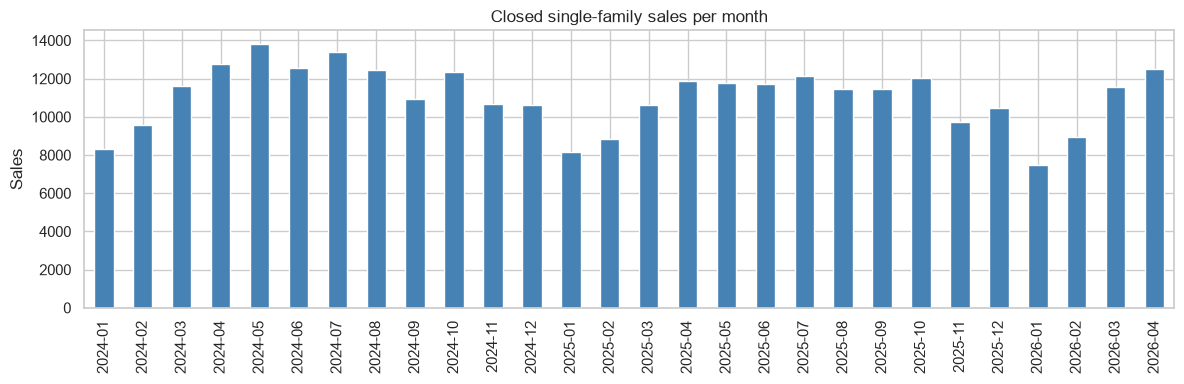

In [10]:
fig, ax = plt.subplots(figsize=(12, 4))
monthly_counts.plot.bar(ax=ax, color="steelblue")
ax.set(title="Closed single-family sales per month", xlabel="", ylabel="Sales")
plt.xticks(rotation=90)
plt.tight_layout()

**Observation:** Data spans 28 months (Jan 1st, 2024 to April 30th, 2026). The number of closings varies between year/months, with the lowest being 7490 and the highest being 13831. There might be some slight seasonality in sale volume (around April to June of each year). Should investigate if this occurs with sale price.

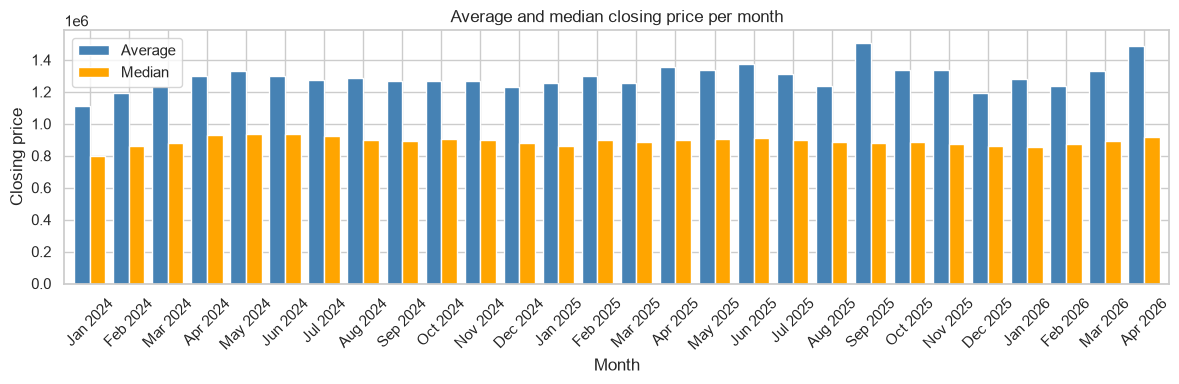

In [11]:
df_viz = df.copy()
df_viz["CloseMonth"] = df_viz["CloseDate"].dt.to_period("M")
monthly_cts_prices = df_viz.groupby("CloseMonth")["ClosePrice"].agg(average = "mean", median = "median")

ax = monthly_cts_prices.plot(kind="bar", figsize=(12, 4), color=["steelblue", "orange"], width=0.8)
ax.set(title="Average and median closing price per month", xlabel="Month", ylabel="Closing price")
ax.legend(["Average", "Median"])
ax.set_xticklabels(
    monthly_cts_prices.index.to_timestamp().strftime("%b %Y"),
    rotation=90
)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Part 2: Can I trust it?
Is each row and each column what I think it is? Nothing gets removed here. Issues are noted for preprocessing.

## 2.1 Grain
Each row should be one closed sale. The raw file had 594 duplicated `ListingKey` values, likely from overlap between monthly exports. Checking whether they're still there after the filter and whether the duplicate rows are actually identical.

In [12]:
print("Duplicated ListingKey:", df["ListingKey"].duplicated().sum())
print("Fully duplicated rows:", df.duplicated().sum())

Duplicated ListingKey: 264
Fully duplicated rows: 29


In [13]:
dup_rows = df[df["ListingKey"].duplicated(keep=False)].sort_values("ListingKey")

# columns whose value differs within at least one duplicated ListingKey
differing = (
    dup_rows.groupby("ListingKey")
    .nunique(dropna=False)
    .gt(1)
    .sum()
    .sort_values(ascending=False)
)
differing[differing > 0]

ContractStatusChangeDate       231
CloseDate                      231
BuyerAgentMlsId                 62
ClosePrice                      60
lonfilled                       60
latfilled                       60
BuyerAgentFirstName             57
BuyerOfficeName                 57
BuyerAgentLastName              56
BuyerOfficeAOR                  44
Latitude                        43
Longitude                       39
PurchaseContractDate            28
BuyerAgentAOR                   28
DaysOnMarket                    22
ListAgentAOR                    18
BuyerAgencyCompensation         16
BuyerAgencyCompensationType     16
OriginatingSystemSubName        12
OriginatingSystemName           12
CoBuyerAgentFirstName            7
ListPrice                        7
CoListOfficeName                 4
ListAgentLastName                2
ListAgentFirstName               2
ListAgentEmail                   2
ListAgentFullName                2
LotSizeAcres                     1
UnparsedAddress     

In [14]:
dup_rows[["ListingKey", "CloseDate", "ClosePrice", "ListPrice", "LivingArea"]].head(10)

,ListingKey,CloseDate,ClosePrice,ListPrice,LivingArea
23245,1031992525,2024-10-18,"459,900.00","459,900.00","1,760.00"
24246,1031992525,2024-06-21,"415,740.00","415,740.00","1,760.00"
26247,1037464932,2024-05-25,"650,000.00","675,000.00","1,012.00"
21199,1037464932,2024-09-06,"665,000.00","675,000.00","1,012.00"
23046,1046689006,2024-10-29,"825,000.00","825,000.00","1,248.00"
23566,1046689006,2024-06-30,"825,000.00","825,000.00","1,248.00"
23352,1048638478,2024-06-25,"6,600,000.00","6,700,000.00","5,621.00"
24069,1048638478,2024-08-21,"6,550,000.00","6,700,000.00","5,621.00"
21835,1052182218,2024-04-26,"355,000.00","349,000.00","1,464.00"
24032,1052182218,2024-08-20,"355,000.00","349,000.00","1,464.00"


In [15]:
raw_month_sizes = pd.to_datetime(df_raw["CloseDate"]).dt.to_period("M").value_counts()
print("Largest monthly file (raw rows):", raw_month_sizes.max())

Largest monthly file (raw rows): 26487


Repeated addresses could be the same house selling more than once in 28 months (a legitimate repeat sale), or something else. Looking at the gap between sales of the same address after removing duplicate `ListingKey` rows.

In [16]:
addr_counts = df["UnparsedAddress"].value_counts()
print("Addresses appearing more than once:", (addr_counts > 1).sum())
addr_counts.value_counts().sort_index()

Addresses appearing more than once: 8853


count
1    291629
2      8752
3        96
4         5
Name: count, dtype: int64

In [17]:
unique_listings = df.drop_duplicates("ListingKey")
repeats = unique_listings[unique_listings["UnparsedAddress"].duplicated(keep=False)].sort_values("CloseDate")
gap_days = repeats.groupby("UnparsedAddress")["CloseDate"].diff().dt.days.dropna()
gap_days.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95])

count   8,697.00
mean      265.71
std       176.42
min         0.00
5%         67.80
25%       133.00
50%       211.00
75%       371.00
95%       630.00
max       837.00
Name: CloseDate, dtype: float64

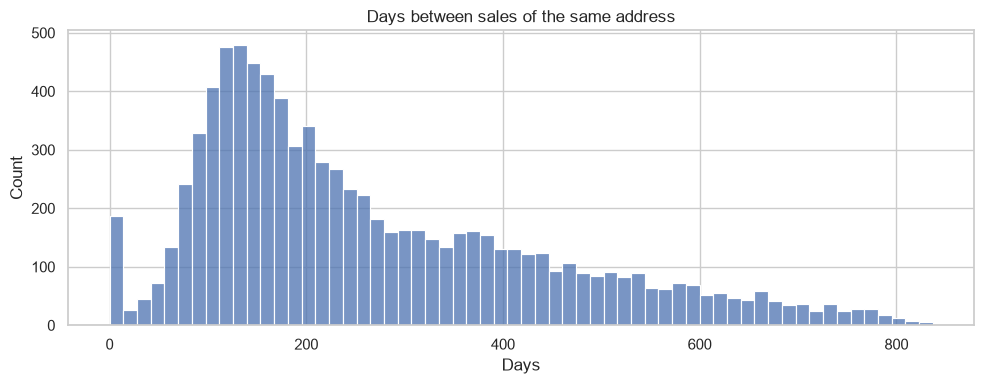

In [18]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(gap_days, bins=60, ax=ax)
ax.set(title="Days between sales of the same address", xlabel="Days", ylabel="Count")
plt.tight_layout()

In [19]:
# addresses with the most repeats are often placeholders or bad data rather than real repeat sales
addr_counts.head(10)

UnparsedAddress
5508 Avenida Maravillas    4
16 Eucalyptus              4
253 Kolmar St              4
1025 Verona Drive          4
627 7th Street             4
4703 Ashworth Street       3
3705 Haines St             3
1739 Cliffbranch Drive     3
10492 Wilmington Lane      3
18116 Rancho Street        3
Name: count, dtype: int64

## 2.2 Missingness
Rough triage: close to 100% missing gets dropped, 85-99% is probably unusable, and 5-40% needs a look at *why* it's missing. The null percentages from the raw file can change after filtering, so they're recalculated here.

In [20]:
null_pct = df.isna().mean().sort_values(ascending=False)
null_pct[null_pct > 0].to_frame("null_pct")

,null_pct
ElementarySchoolDistrict,1.00
AboveGradeFinishedArea,1.00
TaxAnnualAmount,1.00
MiddleOrJuniorSchoolDistrict,1.00
TaxYear,1.00
...,...
ListAgentFullName,0.00
BathroomsTotalInteger,0.00
ListAgentLastName,0.00
ClosePrice,0.00


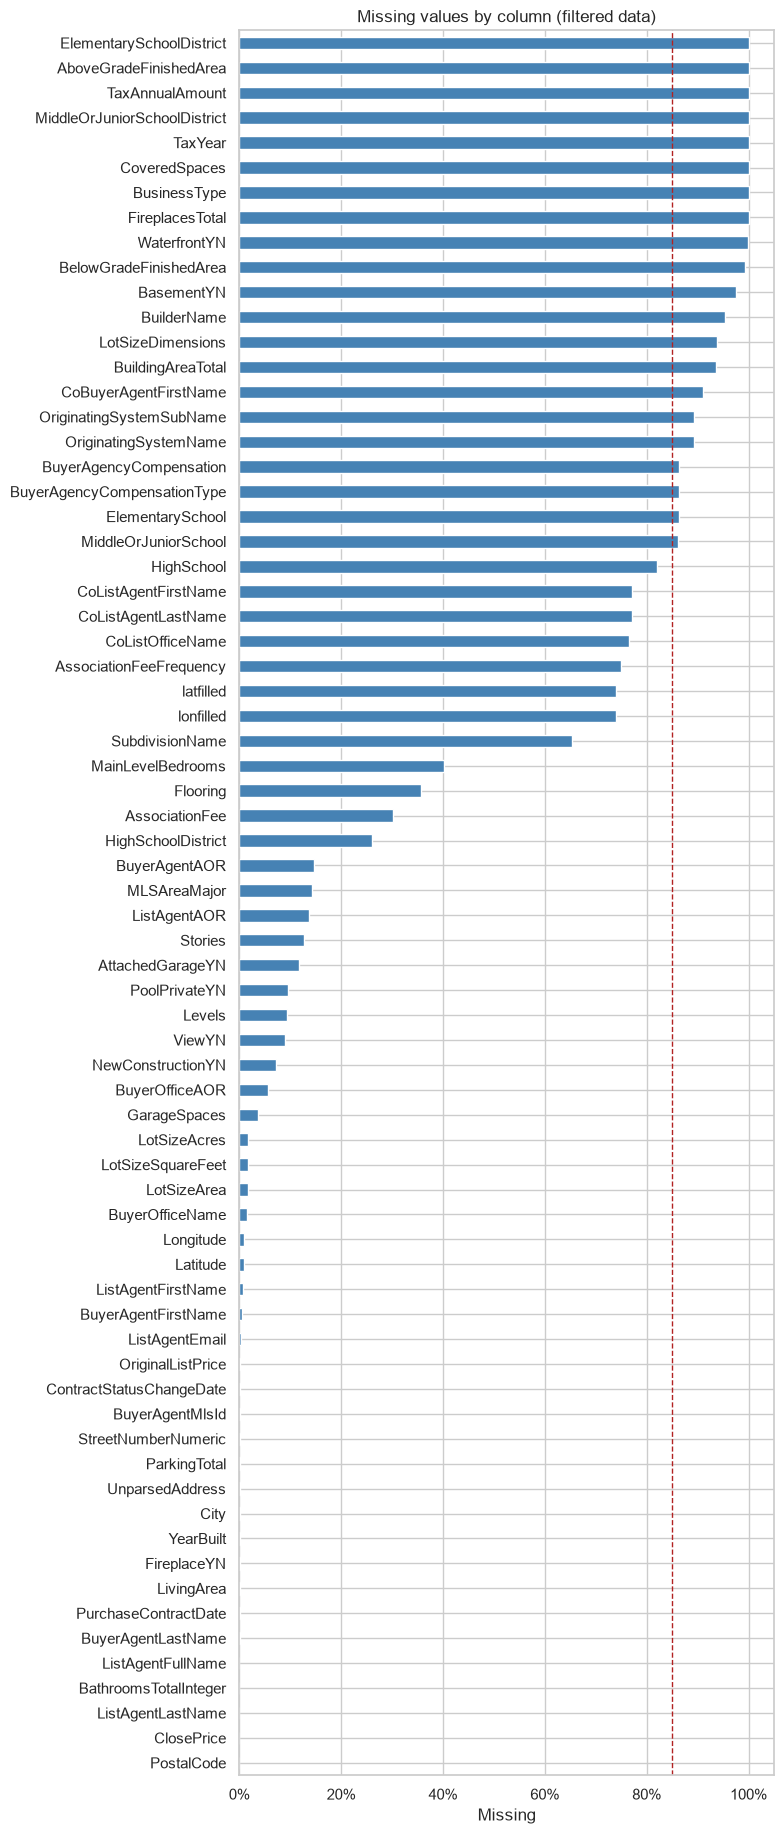

In [21]:
missing = null_pct[null_pct > 0].sort_values()
fig, ax = plt.subplots(figsize=(8, 0.25 * len(missing) + 1))
missing.plot.barh(ax=ax, color="steelblue")
ax.axvline(0.85, color="firebrick", linestyle="--", linewidth=1)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1))
ax.set(title="Missing values by column (filtered data)", xlabel="Missing")
plt.tight_layout()

Checking whether missing values in the core features are spread evenly over time or concentrated in certain months.

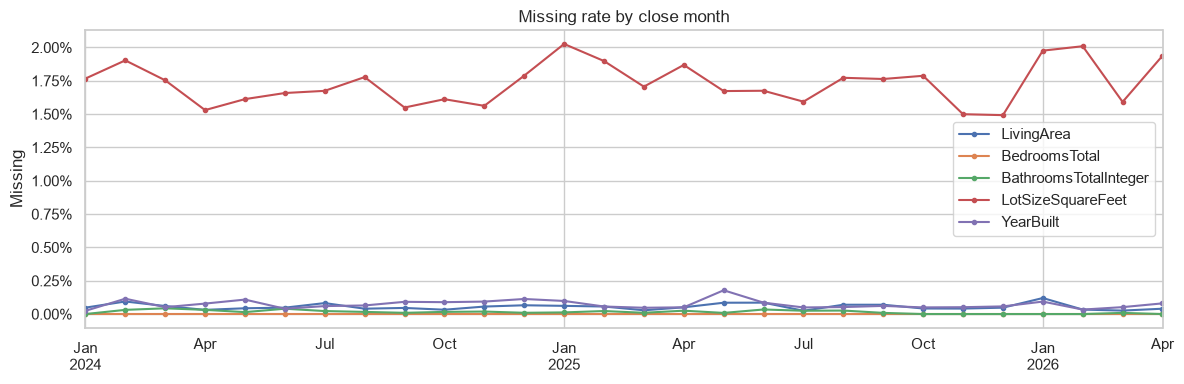

In [22]:
monthly_counts = close_month.value_counts().sort_index()
core_features = ["LivingArea", "BedroomsTotal", "BathroomsTotalInteger", "LotSizeSquareFeet", "YearBuilt"]
missing_by_month = df[core_features].isna().groupby(close_month).mean()

fig, ax = plt.subplots(figsize=(12, 4))
missing_by_month.plot(ax=ax, marker="o", markersize=3)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1))
ax.set(title="Missing rate by close month", xlabel="", ylabel="Missing")
plt.tight_layout()

And by county, for counties with at least 1,000 sales.

In [23]:
county_sizes = df["CountyOrParish"].value_counts()
big_counties = county_sizes[county_sizes >= 1000].index

missing_by_county = (
    df[df["CountyOrParish"].isin(big_counties)]
    .groupby("CountyOrParish")[core_features]
    .apply(lambda g: g.isna().mean())
    .sort_values("LivingArea", ascending=False)
)
missing_by_county.head(15)

,LivingArea,BedroomsTotal,BathroomsTotalInteger,LotSizeSquareFeet,YearBuilt
CountyOrParish,,,,,
Santa Barbara,0.00,0.00,0.00,0.00,0.00
Los Angeles,0.00,0.00,0.00,0.00,0.00
Ventura,0.00,0.00,0.00,0.00,0.00
Kern,0.00,0.00,0.00,0.00,0.00
San Luis Obispo,0.00,0.00,0.00,0.00,0.00
San Bernardino,0.00,0.00,0.00,0.00,0.00
Riverside,0.00,0.00,0.00,0.01,0.00
Madera,0.00,0.00,0.00,0.00,0.00
Merced,0.00,0.00,0.00,0.00,0.00


## 2.3 Validity
For each key numeric column: mean vs median for skew, 99th percentile vs max for typos, and zeros where zero isn't possible.

In [24]:
key_cols = ["ClosePrice", "LivingArea", "BedroomsTotal", "BathroomsTotalInteger",
            "LotSizeSquareFeet", "LotSizeAcres", "LotSizeArea", "YearBuilt"]
df[key_cols].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
ClosePrice,"309,733.00","1,297,553.12","5,643,292.57",0.00,"237,500.00","367,000.00","625,000.00","894,000.00","1,430,000.00","3,175,000.00","6,250,000.00","989,500,000.00"
LivingArea,"309,569.00","2,033.88","1,058.30",0.00,728.00,960.00,"1,376.00","1,804.00","2,421.00","3,809.00","5,649.00","123,764.00"
BedroomsTotal,"309,735.00",3.48,0.96,0.00,2.00,2.00,3.00,3.00,4.00,5.00,6.00,45.00
BathroomsTotalInteger,"309,685.00",2.62,1.20,0.00,1.00,1.00,2.00,2.00,3.00,5.00,6.00,175.00
LotSizeSquareFeet,"304,408.00","266,665.18","14,602,826.47",0.00,"1,790.00","3,239.00","5,663.00","7,245.00","10,350.00","49,296.00","252,648.00","2,087,220,960.00"
LotSizeAcres,"304,381.00",38.11,"14,211.63",0.00,0.04,0.07,0.13,0.17,0.24,1.14,5.84,"7,810,698.36"
LotSizeArea,"304,432.00","20,942.66","704,952.97",0.00,0.30,"2,450.00","5,466.00","7,100.00","9,906.00","40,511.45","216,929.00","217,800,000.00"
YearBuilt,"309,510.00","1,975.63",27.50,"1,776.00","1,910.00","1,927.00","1,956.00","1,976.00","1,998.00","2,022.00","2,025.00","2,026.00"


In [25]:
(df[key_cols] == 0).sum().to_frame("zeros")

,zeros
ClosePrice,1
LivingArea,126
BedroomsTotal,176
BathroomsTotalInteger,132
LotSizeSquareFeet,162
LotSizeAcres,432
LotSizeArea,163
YearBuilt,0


In [26]:
pd.DataFrame({col: df[col].nlargest(10).to_numpy() for col in key_cols})

,ClosePrice,LivingArea,BedroomsTotal,BathroomsTotalInteger,LotSizeSquareFeet,LotSizeAcres,LotSizeArea,YearBuilt
0,"989,500,000.00","123,764.00",45.00,175.00,"2,087,220,960.00","7,810,698.36","217,800,000.00","2,026.00"
1,"970,000,000.00","56,500.00",34.00,153.00,"1,938,942,720.00","571,837.00","209,091,916.00","2,026.00"
2,"900,000,000.00","33,652.00",31.00,45.00,"1,897,473,600.00","127,631.00","135,036,000.00","2,026.00"
3,"875,000,000.00","32,644.00",22.00,35.00,"1,897,473,600.00","94,090.00","112,123,440.00","2,026.00"
4,"835,800,000.00","32,500.00",19.00,31.00,"1,897,473,600.00","88,862.00","110,978,248.00","2,026.00"
5,"815,000,000.00","31,068.00",17.00,27.00,"1,897,473,600.00","87,991.00","76,012,200.00","2,026.00"
6,"796,000,000.00","30,500.00",16.00,27.00,"1,821,592,080.00","87,991.00","43,790,868.00","2,026.00"
7,"768,500,000.00","26,627.00",16.00,25.00,"1,802,599,920.00","87,120.00","41,861,160.00","2,026.00"
8,"751,412,000.00","24,350.00",15.00,23.00,"1,633,500,000.00","86,248.00","31,642,419.00","2,026.00"
9,"740,000,000.00","23,727.00",15.00,22.00,"1,432,688,400.00","81,282.00","24,567,840.00","2,026.00"


Counting rows past some rough plausibility lines. These thresholds aren't final, just a way to see how many rows are affected.

In [27]:
close_year = df["CloseDate"].dt.year
flags = pd.Series({
    "ClosePrice < $50K": (df["ClosePrice"] < 50_000).sum(),
    "ClosePrice > $50M": (df["ClosePrice"] > 50_000_000).sum(),
    "LivingArea < 300": (df["LivingArea"] < 300).sum(),
    "LivingArea > 15,000": (df["LivingArea"] > 15_000).sum(),
    "BedroomsTotal == 0": (df["BedroomsTotal"] == 0).sum(),
    "BedroomsTotal > 15": (df["BedroomsTotal"] > 15).sum(),
    "BathroomsTotalInteger == 0": (df["BathroomsTotalInteger"] == 0).sum(),
    "BathroomsTotalInteger > 15": (df["BathroomsTotalInteger"] > 15).sum(),
    "YearBuilt < 1850": (df["YearBuilt"] < 1850).sum(),
    "YearBuilt > close year + 1": (df["YearBuilt"] > close_year + 1).sum(),
})
flags.to_frame("rows")

,rows
ClosePrice < $50K,86
ClosePrice > $50M,31
LivingArea < 300,151
"LivingArea > 15,000",48
BedroomsTotal == 0,176
BedroomsTotal > 15,8
BathroomsTotalInteger == 0,132
BathroomsTotalInteger > 15,26
YearBuilt < 1850,9
YearBuilt > close year + 1,0


### Lot size columns
There are three lot size columns. `LotSizeSquareFeet` should equal `LotSizeAcres` x 43,560. `LotSizeArea` has no unit column, so checking which of the other two it matches row by row.

In [28]:
sqft_vs_acres = df["LotSizeSquareFeet"] / (df["LotSizeAcres"] * 43_560)
valid = sqft_vs_acres.replace([np.inf, -np.inf], np.nan).dropna()
print(f"Rows where sqft and acres agree within 1%: {valid.between(0.99, 1.01).mean():.1%} of {len(valid):,}")
valid.describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99])

Rows where sqft and acres agree within 1%: 99.9% of 303,929


count   303,929.00
mean          1.00
std           0.01
min           0.21
1%            1.00
5%            1.00
50%           1.00
95%           1.00
99%           1.00
max           4.68
dtype: float64

In [29]:
area_unit = np.select(
    [
        df["LotSizeArea"].isna(),
        np.isclose(df["LotSizeArea"], df["LotSizeSquareFeet"], rtol=0.01),
        np.isclose(df["LotSizeArea"], df["LotSizeAcres"], rtol=0.01),
    ],
    ["missing", "matches sqft", "matches acres"],
    default="matches neither",
)
pd.Series(area_unit).value_counts()

matches sqft       295715
matches acres        8711
missing              5303
matches neither         6
Name: count, dtype: int64

### Dates
For a normal sale, `ListingContractDate` <= `PurchaseContractDate` <= `CloseDate`. The raw file had purchase dates from 1923 and after the last close date.

In [30]:
date_checks = pd.Series({
    "Listing after purchase contract": (df["ListingContractDate"] > df["PurchaseContractDate"]).sum(),
    "Purchase contract after close": (df["PurchaseContractDate"] > df["CloseDate"]).sum(),
    "Listing after close": (df["ListingContractDate"] > df["CloseDate"]).sum(),
})
date_checks.to_frame("rows")

,rows
Listing after purchase contract,187
Purchase contract after close,196
Listing after close,44


In [31]:
days_listed_to_close = (df["CloseDate"] - df["ListingContractDate"]).dt.days
days_listed_to_close.describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99])

count   309,735.00
mean         75.83
std          71.22
min         -31.00
1%            1.00
5%           22.00
50%          56.00
95%         193.00
99%         326.00
max      14,758.00
dtype: float64

### Geography
The raw file had 25 values in `StateOrProvince` and 63 counties, while California has 58. Also checking for coordinates outside California.

In [32]:
df["StateOrProvince"].value_counts(dropna=False)

StateOrProvince
CA    309713
AZ         8
OS         3
NV         2
CO         2
TX         1
GA         1
ME         1
NY         1
MO         1
TN         1
FL         1
Name: count, dtype: int64

In [33]:
print("Counties:", df["CountyOrParish"].nunique())
df["CountyOrParish"].value_counts().tail(15)

Counties: 63


CountyOrParish
Amador             23
Colusa             23
Other State        12
Lassen             12
Humboldt           11
Other               8
Inyo                6
Other County        5
Mono                5
Foreign Country     4
Modoc               2
Alpine              1
Del Norte           1
Clark               1
Sierra              1
Name: count, dtype: int64

In [34]:
# rough bounding box for California
in_ca_box = df["Latitude"].between(32.4, 42.1) & df["Longitude"].between(-124.5, -114.1)
has_coords = df["Latitude"].notna() & df["Longitude"].notna()
print("Missing coordinates:", (~has_coords).sum())
print("Coordinates outside CA box:", (has_coords & ~in_ca_box).sum())
print("Latitude or longitude == 0:", ((df["Latitude"] == 0) | (df["Longitude"] == 0)).sum())

Missing coordinates: 2712
Coordinates outside CA box: 76
Latitude or longitude == 0: 22


In [35]:
df[["latfilled", "lonfilled"]].value_counts(dropna=False)

latfilled  lonfilled
NaN        NaN          229136
False      False         46789
True       True          33810
Name: count, dtype: int64

## 2.4 Column roles
Every column is assigned to one role. The question for leakage is whether the value would be known before the house is listed. Leakage columns stay in the data for now since `ListPrice` is useful for sanity checking `ClosePrice` in Part 3. They get dropped in preprocessing.

In [36]:
column_roles = {
    "target": ["ClosePrice"],
    "time": ["CloseDate"],
    "id": ["ListingKey", "ListingKeyNumeric", "ListingId", "UnparsedAddress", "StreetNumberNumeric"],
    "pre_listing": [
        "LivingArea", "BedroomsTotal", "BathroomsTotalInteger", "MainLevelBedrooms",
        "LotSizeSquareFeet", "LotSizeAcres", "LotSizeArea", "BuildingAreaTotal",
        "YearBuilt", "Stories", "Levels", "NewConstructionYN",
        "GarageSpaces", "AttachedGarageYN", "ParkingTotal",
        "PoolPrivateYN", "ViewYN", "FireplaceYN",
        "AssociationFee", "AssociationFeeFrequency",
        "Latitude", "Longitude", "City", "PostalCode", "CountyOrParish", "StateOrProvince",
        "MLSAreaMajor", "SubdivisionName",
        "ElementarySchool", "MiddleOrJuniorSchool", "HighSchool", "HighSchoolDistrict",
    ],
    "leakage": [
        "ListPrice", "OriginalListPrice", "DaysOnMarket",
        "ListingContractDate", "PurchaseContractDate", "ContractStatusChangeDate",
        "ListOfficeName", "CoListOfficeName", "BuyerOfficeName",
        "ListAgentAOR", "BuyerAgentAOR", "BuyerOfficeAOR",
        "BuyerAgencyCompensation", "BuyerAgencyCompensationType",
    ],
    "pii": [
        "ListAgentEmail", "ListAgentFirstName", "ListAgentLastName", "ListAgentFullName",
        "CoListAgentFirstName", "CoListAgentLastName",
        "BuyerAgentMlsId", "BuyerAgentFirstName", "BuyerAgentLastName", "CoBuyerAgentFirstName",
    ],
    "empty": [
        "FireplacesTotal", "AboveGradeFinishedArea", "CoveredSpaces",
        "ElementarySchoolDistrict", "MiddleOrJuniorSchoolDistrict",
        "TaxAnnualAmount", "TaxYear", "BelowGradeFinishedArea", "BusinessType", "WaterfrontYN",
    ],
    "drop_other": [
        "Unnamed: 0", "MlsStatus", "PropertyType", "PropertySubType",
        "OriginatingSystemName", "OriginatingSystemSubName",
    ],
    "unsure": ["Flooring", "BasementYN", "BuilderName", "LotSizeDimensions", "latfilled", "lonfilled"],
}

In [37]:
assigned = [c for cols in column_roles.values() for c in cols]
print("Unassigned:", sorted(set(df.columns) - set(assigned)))
print("Assigned twice:", sorted({c for c in assigned if assigned.count(c) > 1}))
print("Not in df:", sorted(set(assigned) - set(df.columns)))
pd.Series({role: len(cols) for role, cols in column_roles.items()}).to_frame("columns")

Unassigned: []
Assigned twice: []
Not in df: ['Unnamed: 0']


,columns
target,1
time,1
id,5
pre_listing,32
leakage,14
pii,10
empty,10
drop_other,6
unsure,6


Notes on some of the choices:

- `UnparsedAddress` and `StreetNumberNumeric` are under `id` since they identify a property, not describe it. They're needed for finding repeat sales.
- `ListingContractDate` is the date the listing agreement was signed, so it doesn't exist before listing.
- Office names and AOR (association of realtors) columns aren't personal info but are only known once agents are involved.
- `WaterfrontYN` and `BusinessType` are over 99% missing. `TaxAnnualAmount` would be a strong pre-listing feature if it were populated, but it isn't.
- `PropertyType` and `PropertySubType` are constant after the filter.

**Unsure:**
- `Flooring`: technically a property feature, but it's usually written at listing time and is free text.
- `BasementYN`: only one non-null value, so a blank might mean "no basement" or might mean unknown.
- `BuilderName`: mostly missing, probably only filled for new construction.
- `LotSizeDimensions`: free text and 95% missing. Redundant with the lot size columns.
- `latfilled` / `lonfilled`: not standard CRMLS fields. [TODO: confirm where these came from]

# Part 3: What does it tell me?
How is `ClosePrice` distributed, and what drives it?

Some plots limit the axis range or use a cleaner subset so the bulk of the data is visible past the typos found in 2.3. This only affects the plots. No rows are removed from `df`.

## 3.1 Target: ClosePrice

In [38]:
print("Missing ClosePrice:", df["ClosePrice"].isna().sum())
price = df["ClosePrice"].dropna()
lo, hi = price.quantile([0.01, 0.99])
print(f"1st-99th percentile: ${lo:,.0f} to ${hi:,.0f}")

Missing ClosePrice: 2
1st-99th percentile: $237,500 to $6,250,000


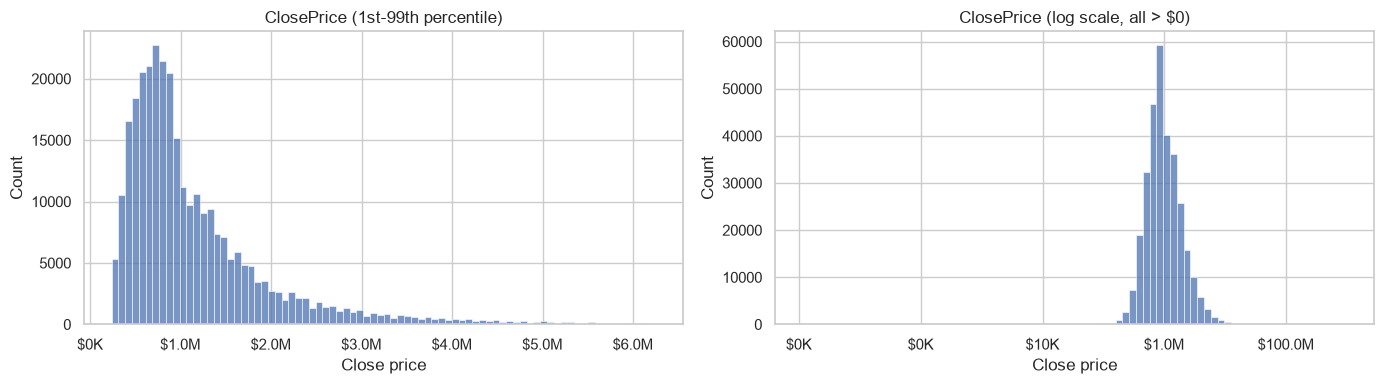

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(price[price.between(lo, hi)], bins=80, ax=axes[0])
axes[0].xaxis.set_major_formatter(money_fmt)
axes[0].set(title="ClosePrice (1st-99th percentile)", xlabel="Close price")

sns.histplot(price[price > 0], bins=80, log_scale=True, ax=axes[1])
axes[1].xaxis.set_major_formatter(money_fmt)
axes[1].set(title="ClosePrice (log scale, all > $0)", xlabel="Close price")

plt.tight_layout()

Looking at the low end separately. Prices in the thousands could be rentals that were entered as single-family sales.

In [40]:
low = df[df["ClosePrice"] < 50_000]
print(f"Rows under $50K: {len(low):,}")
low[["ClosePrice", "ListPrice", "LivingArea", "DaysOnMarket"]].describe()

Rows under $50K: 86


,ClosePrice,ListPrice,LivingArea,DaysOnMarket
count,86.00,86.00,86.00,86.00
mean,"30,566.78","282,173.15","1,230.36",68.26
std,"13,537.88","421,462.86",661.66,77.11
min,0.00,"8,000.00",192.00,0.00
25%,"22,375.00","34,925.00",843.00,16.00
50%,"31,250.00","65,000.00","1,165.00",43.00
75%,"41,250.00","403,725.00","1,500.00",84.75
max,"49,900.00","2,000,000.00","3,886.00",332.00


### Sale-to-list ratio
Most homes sell somewhere near list price, so `ClosePrice / ListPrice` far from 1 is a good sign of a typo in one of the two. `ListPrice` can't be a model feature but it works for checking the target.

In [41]:
sale_to_list = (df["ClosePrice"] / df["ListPrice"]).replace([np.inf, -np.inf], np.nan)
print("Ratio < 0.5:", (sale_to_list < 0.5).sum())
print("Ratio > 2:", (sale_to_list > 2).sum())
sale_to_list.describe(percentiles=[0.001, 0.01, 0.05, 0.5, 0.95, 0.99, 0.999])

Ratio < 0.5: 117
Ratio > 2: 118


count   309,733.00
mean          1.07
std           7.45
min           0.00
0.1%          0.67
1%            0.84
5%            0.92
50%           1.00
95%           1.12
99%           1.28
99.9%         1.61
max       1,153.85
dtype: float64

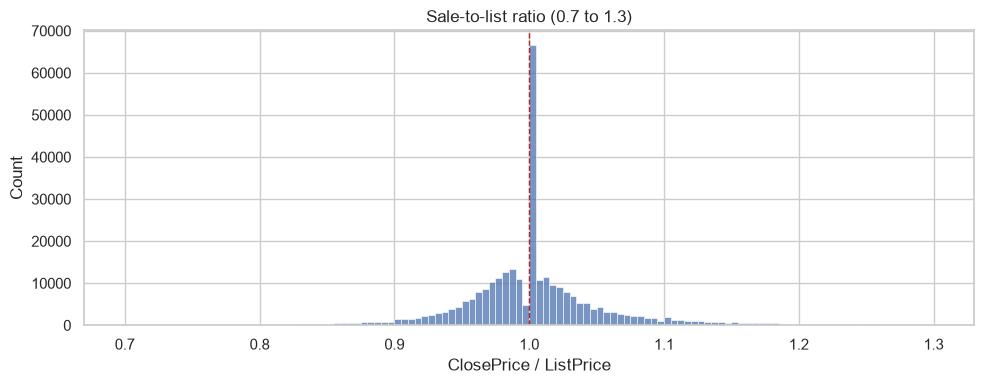

In [42]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(sale_to_list[sale_to_list.between(0.7, 1.3)], bins=120, ax=ax)
ax.axvline(1, color="firebrick", linestyle="--", linewidth=1)
ax.set(title="Sale-to-list ratio (0.7 to 1.3)", xlabel="ClosePrice / ListPrice")
plt.tight_layout()

**Observation:** [TODO: median price, skew, whether log price looks roughly symmetric, what the low-end rows look like, how many rows have an extreme sale-to-list ratio]

**Preprocessing:** [TODO: model log(ClosePrice)? price floor/ceiling? drop rows with extreme sale-to-list ratio? handle missing ClosePrice]

## 3.2 Key features
`LivingArea`, `BedroomsTotal`, `BathroomsTotalInteger`, and lot size. `LotSizeSquareFeet` is used here pending the decision in 2.3.

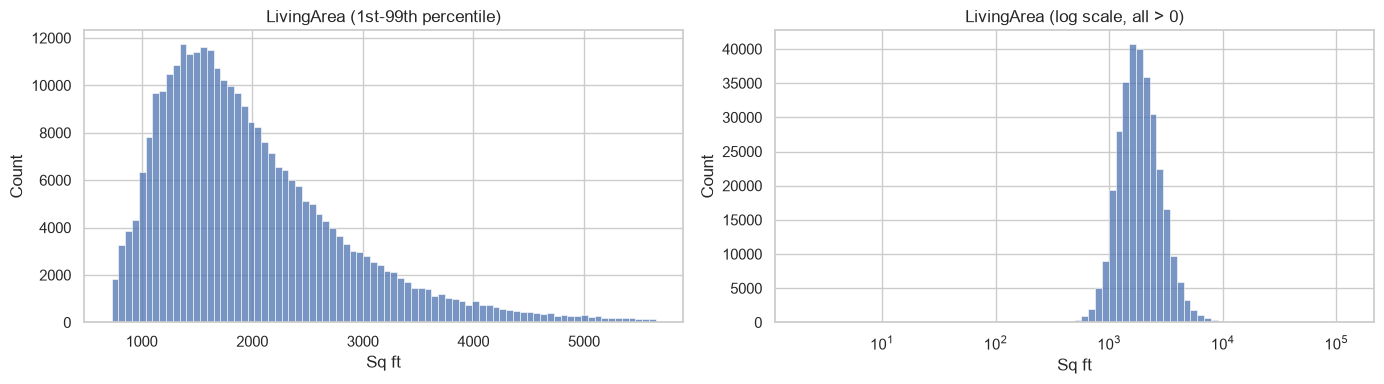

In [43]:
living = df["LivingArea"].dropna()
la_lo, la_hi = living.quantile([0.01, 0.99])

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(living[living.between(la_lo, la_hi)], bins=80, ax=axes[0])
axes[0].set(title="LivingArea (1st-99th percentile)", xlabel="Sq ft")
sns.histplot(living[living > 0], bins=80, log_scale=True, ax=axes[1])
axes[1].set(title="LivingArea (log scale, all > 0)", xlabel="Sq ft")
plt.tight_layout()

BedroomsTotal > 10: 48 rows
BathroomsTotalInteger > 10: 179 rows


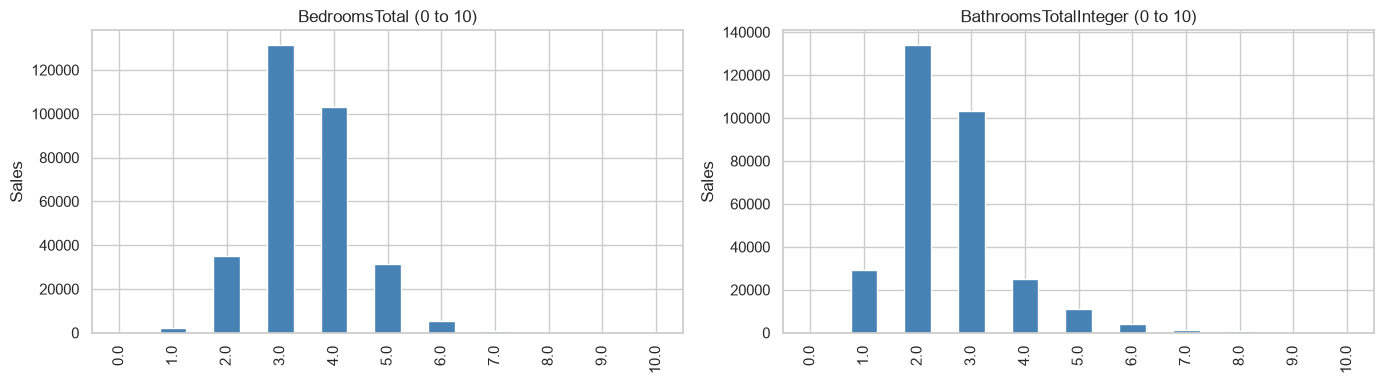

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col in zip(axes, ["BedroomsTotal", "BathroomsTotalInteger"]):
    counts = df[col].value_counts().sort_index()
    counts[counts.index <= 10].plot.bar(ax=ax, color="steelblue")
    ax.set(title=f"{col} (0 to 10)", xlabel="", ylabel="Sales")
    print(f"{col} > 10: {(df[col] > 10).sum()} rows")
plt.tight_layout()

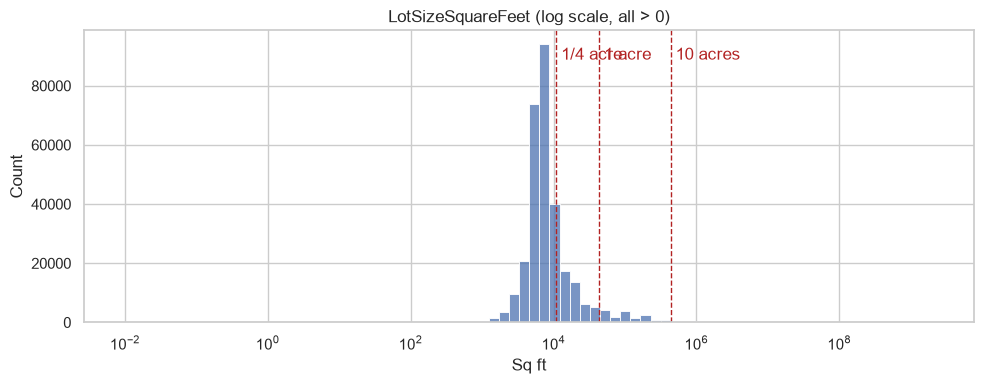

In [45]:
lot = df["LotSizeSquareFeet"].dropna()

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(lot[lot > 0], bins=80, log_scale=True, ax=ax)
for acres, label in [(0.25, "1/4 acre"), (1, "1 acre"), (10, "10 acres")]:
    ax.axvline(acres * 43_560, color="firebrick", linestyle="--", linewidth=1)
    ax.text(acres * 43_560, ax.get_ylim()[1] * 0.9, f" {label}", color="firebrick")
ax.set(title="LotSizeSquareFeet (log scale, all > 0)", xlabel="Sq ft")
plt.tight_layout()

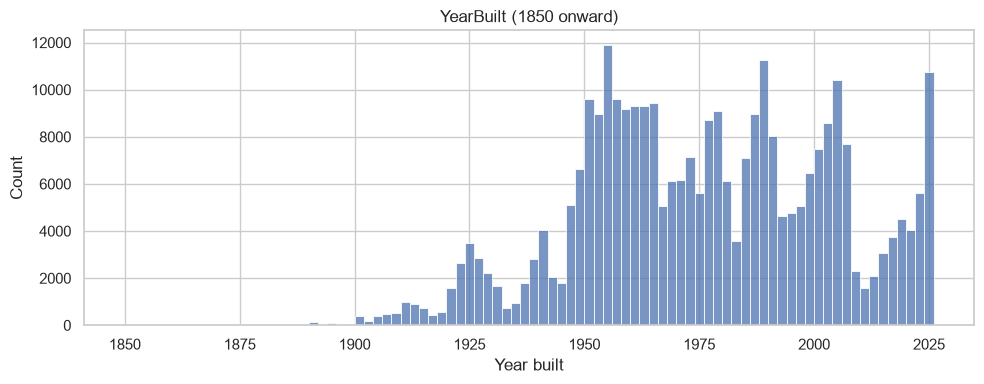

In [46]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(df.loc[df["YearBuilt"] >= 1850, "YearBuilt"], bins=range(1850, 2028, 2), ax=ax)
ax.set(title="YearBuilt (1850 onward)", xlabel="Year built")
plt.tight_layout()

## 3.3 Relationships with price
For these plots, `plot_df` is limited to rows with a plausible price and living area so the typos don't flatten everything. Scatter-style plots use hexbins since there are too many rows for a normal scatter.

In [47]:
plot_df = df[
    df["ClosePrice"].between(50_000, 50_000_000)
    & df["LivingArea"].between(300, 15_000)
].copy()
plot_df["PricePerSqft"] = plot_df["ClosePrice"] / plot_df["LivingArea"]
print(f"{len(plot_df):,} of {len(df):,} rows used for plots")

309,261 of 309,735 rows used for plots


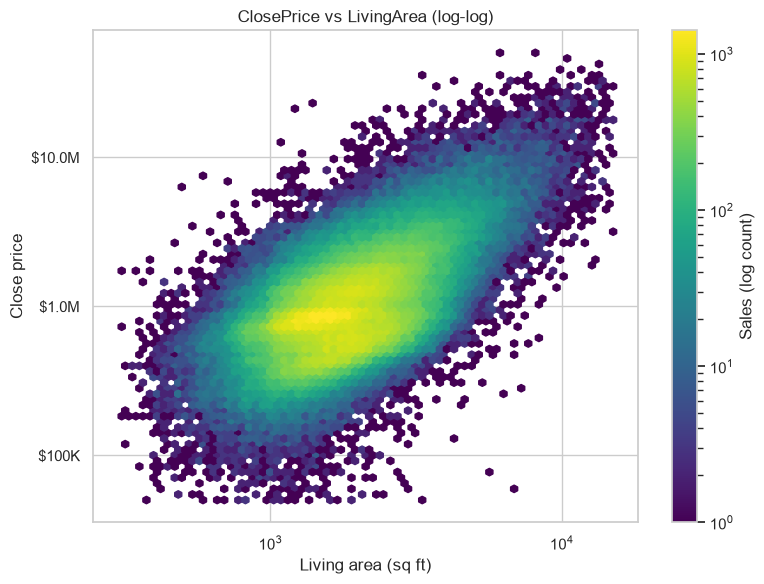

In [48]:
fig, ax = plt.subplots(figsize=(8, 6))
hb = ax.hexbin(plot_df["LivingArea"], plot_df["ClosePrice"],
               xscale="log", yscale="log", gridsize=70, bins="log", cmap="viridis", mincnt=1)
fig.colorbar(hb, ax=ax, label="Sales (log count)")
ax.yaxis.set_major_formatter(money_fmt)
ax.set(title="ClosePrice vs LivingArea (log-log)", xlabel="Living area (sq ft)", ylabel="Close price")
plt.tight_layout()

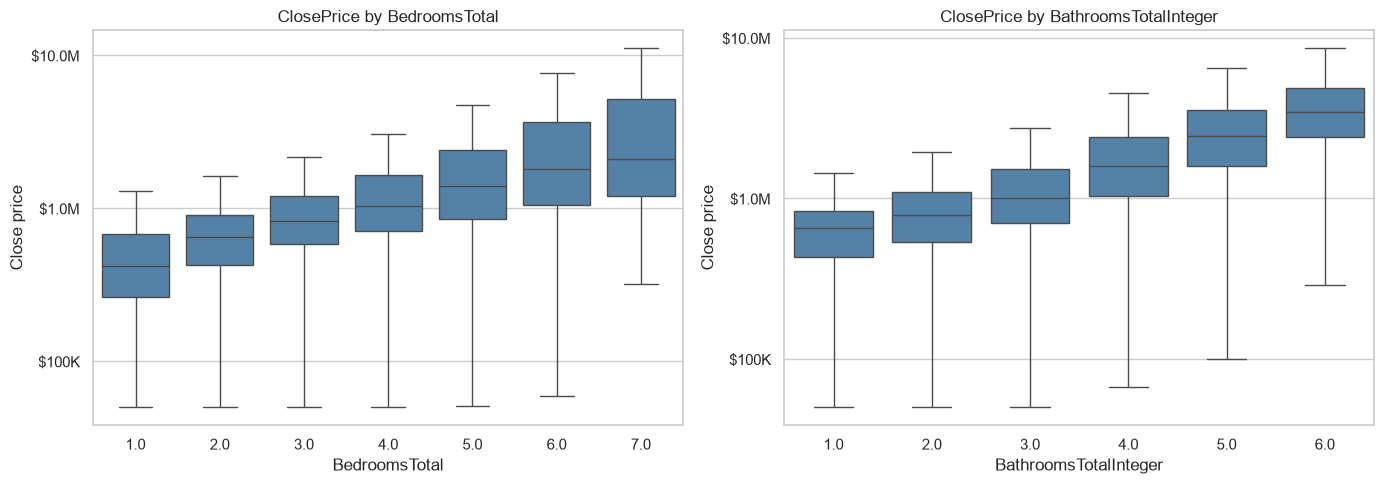

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col, max_val in [(axes[0], "BedroomsTotal", 7), (axes[1], "BathroomsTotalInteger", 6)]:
    subset = plot_df[plot_df[col].between(1, max_val)]
    sns.boxplot(data=subset, x=col, y="ClosePrice", ax=ax, showfliers=False, color="steelblue")
    ax.set_yscale("log")
    ax.yaxis.set_major_formatter(money_fmt)
    ax.set(title=f"ClosePrice by {col}", xlabel=col, ylabel="Close price")
plt.tight_layout()

More bedrooms usually means a bigger house, so the plot above mixes the effect of bedrooms with the effect of size. Holding size roughly fixed shows whether bedrooms add anything on their own.

In [50]:
size_bins = [1000, 1500, 2000, 2500, 3000]
size_bin = pd.cut(plot_df["LivingArea"], bins=size_bins)
beds = plot_df["BedroomsTotal"].where(plot_df["BedroomsTotal"].between(2, 5))

beds_at_size = plot_df.groupby([size_bin, beds], observed=True)["ClosePrice"].agg(["median", "size"])
beds_at_size = beds_at_size[beds_at_size["size"] >= 100]
beds_at_size["median"].unstack()

BedroomsTotal,2.00,3.00,4.00,5.00
LivingArea,,,,
"(1000, 1500]","680,000.00","750,000.00","770,000.00","682,500.00"
"(1500, 2000]","710,000.00","857,000.00","870,000.00","875,000.00"
"(2000, 2500]","750,000.00","1,075,000.00","1,045,000.00","1,045,000.00"
"(2500, 3000]","1,101,500.00","1,385,000.00","1,280,000.00","1,150,000.00"


count   309,261.00
mean        609.04
std         381.84
min           8.89
1%          169.66
5%          223.85
50%         532.73
95%       1,276.07
99%       1,949.56
max      18,333.33
Name: PricePerSqft, dtype: float64

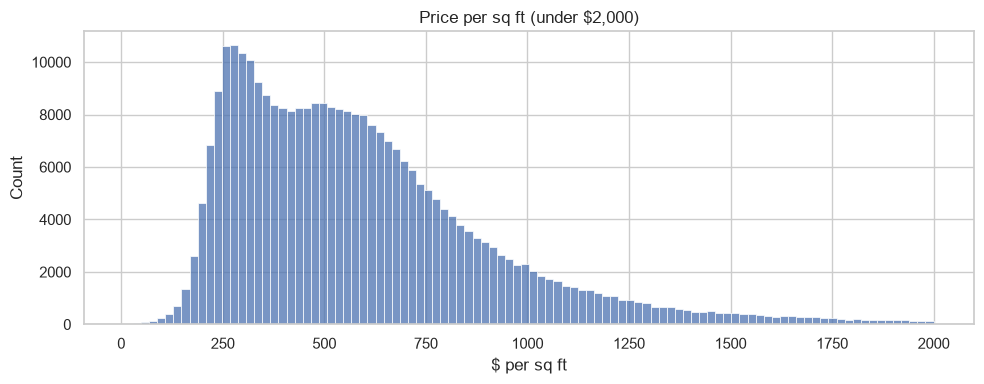

In [51]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(plot_df.loc[plot_df["PricePerSqft"] < 2000, "PricePerSqft"], bins=100, ax=ax)
ax.set(title="Price per sq ft (under $2,000)", xlabel="$ per sq ft")
plt.tight_layout()
plot_df["PricePerSqft"].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99])

Spearman correlation is used since it works on ranks, so the skew and outliers don't dominate the result.

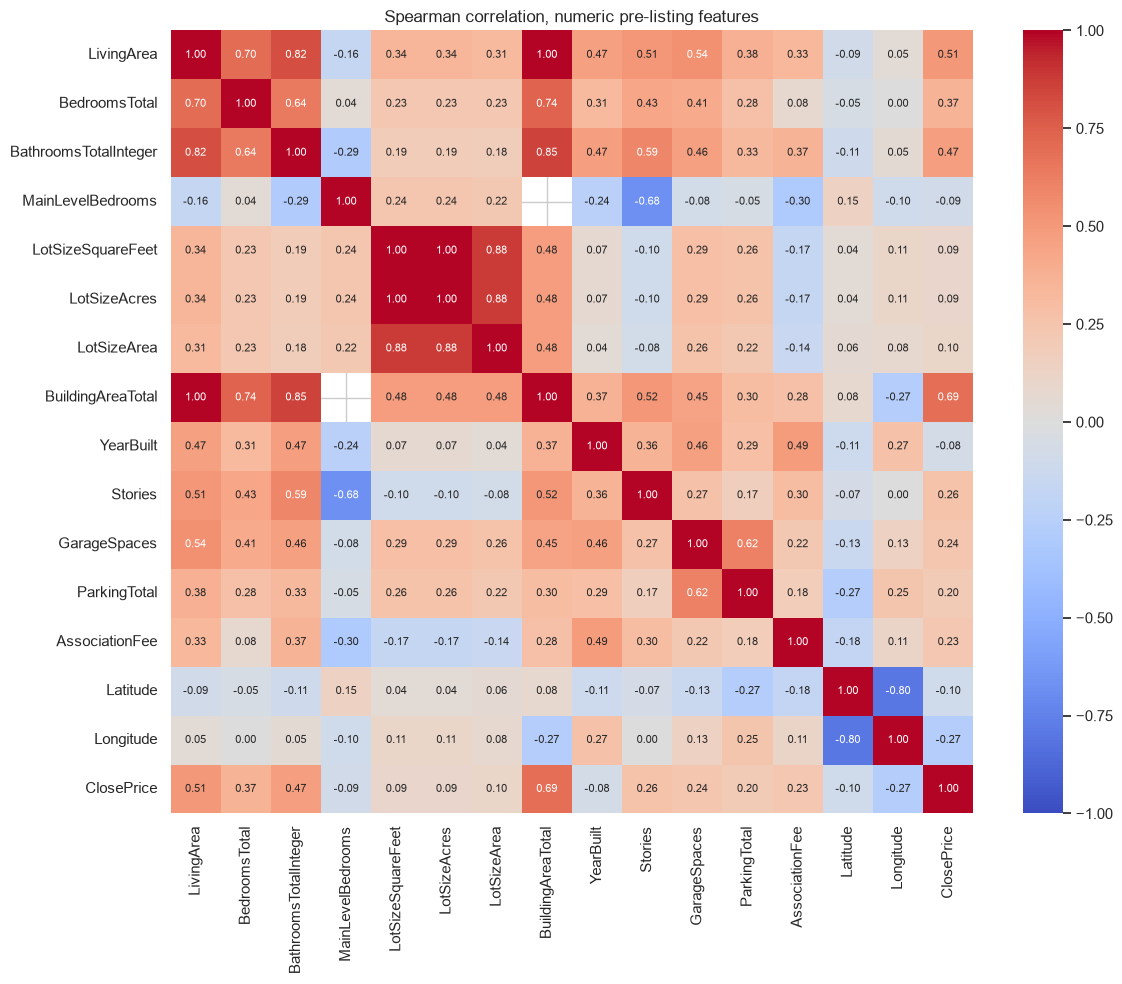

In [52]:
numeric_pre_listing = [c for c in column_roles["pre_listing"] if pd.api.types.is_numeric_dtype(df[c])]
corr = df[numeric_pre_listing + ["ClosePrice"]].corr(method="spearman")

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax, annot_kws={"size": 8})
ax.set_title("Spearman correlation, numeric pre-listing features")
plt.tight_layout()

In [53]:
corr["ClosePrice"].drop("ClosePrice").sort_values(ascending=False).to_frame("spearman_with_price")

,spearman_with_price
BuildingAreaTotal,0.69
LivingArea,0.51
BathroomsTotalInteger,0.47
BedroomsTotal,0.37
Stories,0.26
GarageSpaces,0.24
AssociationFee,0.23
ParkingTotal,0.20
LotSizeArea,0.10
LotSizeSquareFeet,0.09


Median price for the yes/no features.

In [54]:
flag_cols = ["ViewYN", "PoolPrivateYN", "FireplaceYN", "AttachedGarageYN", "NewConstructionYN"]
pd.concat(
    {col: df.groupby(df[col].astype("string"), dropna=False)["ClosePrice"].agg(["median", "size"]) for col in flag_cols}
)

median    size
                  ViewYN                     
ViewYN            False    865,000.00  111852
                  True     905,000.00  170271
                  <NA>     950,000.00   27612
PoolPrivateYN     False    820,000.00  234273
                  True   1,115,000.00   45671
                  <NA>   1,710,000.00   29791
FireplaceYN       False    714,000.00   84460
                  True   1,005,000.00  225069
                  <NA>   1,442,750.00     206
AttachedGarageYN  False    882,500.00   45725
                  True     899,000.00  227971
                  <NA>     880,000.00   36039
NewConstructionYN False    895,000.00  276195
                  True     648,348.00   11051
                  <NA>     995,000.00   22489

## 3.4 Time
How much do prices move over the 28 months? If they drift a lot, the model needs to know when a sale happens, and testing should use a time-based split (train on older sales, test on newer ones) instead of a random split.

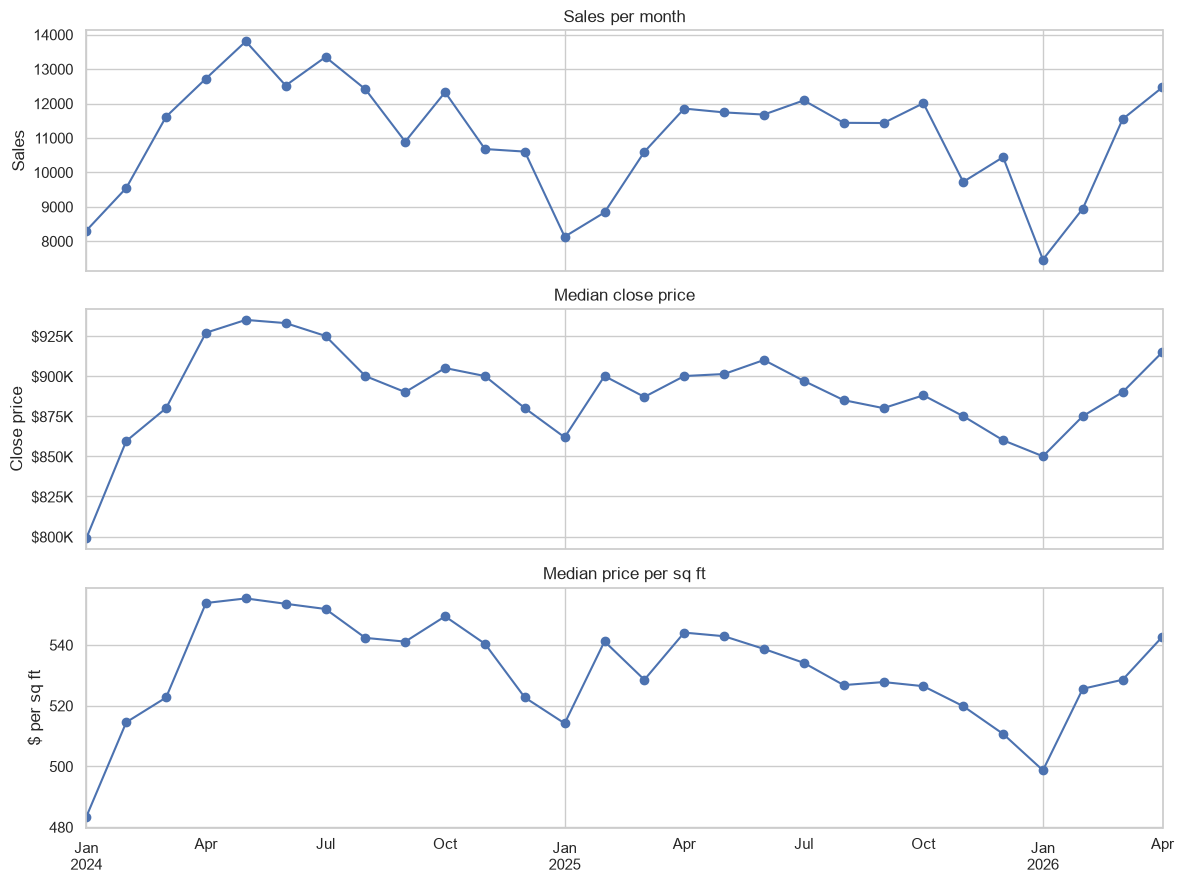

In [55]:
plot_month = plot_df["CloseDate"].dt.to_period("M")
monthly = plot_df.groupby(plot_month).agg(
    sales=("ClosePrice", "size"),
    median_price=("ClosePrice", "median"),
    median_ppsf=("PricePerSqft", "median"),
)
monthly.index = monthly.index.to_timestamp()

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
monthly["sales"].plot(ax=axes[0], marker="o")
axes[0].set(title="Sales per month", ylabel="Sales")
monthly["median_price"].plot(ax=axes[1], marker="o")
axes[1].yaxis.set_major_formatter(money_fmt)
axes[1].set(title="Median close price", ylabel="Close price")
monthly["median_ppsf"].plot(ax=axes[2], marker="o")
axes[2].set(title="Median price per sq ft", ylabel="$ per sq ft", xlabel="")
plt.tight_layout()

Price per sq ft is included because the median price alone can move just from a different mix of homes selling (e.g. more large homes in summer).

In [56]:
first, last = monthly.iloc[:3], monthly.iloc[-3:]
change = (last[["median_price", "median_ppsf"]].mean() / first[["median_price", "median_ppsf"]].mean() - 1)
print(f"First 3 months vs last 3 months:\n{change.map('{:.1%}'.format)}")

First 3 months vs last 3 months:
median_price    5.6%
median_ppsf     5.0%
dtype: str


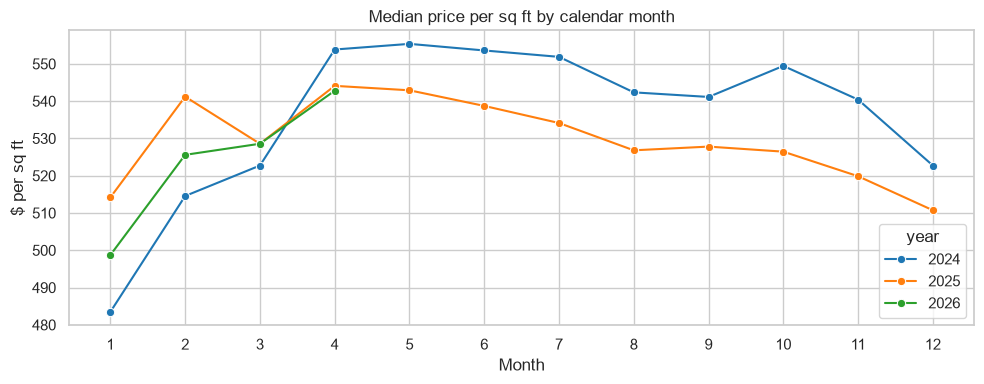

In [57]:
seasonal = monthly.assign(year=monthly.index.year, month=monthly.index.month)

fig, ax = plt.subplots(figsize=(10, 4))
sns.lineplot(data=seasonal, x="month", y="median_ppsf", hue="year", marker="o", palette="tab10", ax=ax)
ax.set(title="Median price per sq ft by calendar month", xlabel="Month", ylabel="$ per sq ft", xticks=range(1, 13))
plt.tight_layout()

## 3.5 Geography
Location is usually the biggest driver of price after size.

In [58]:
county_stats = (
    plot_df.groupby("CountyOrParish")
    .agg(sales=("ClosePrice", "size"), median_price=("ClosePrice", "median"), median_ppsf=("PricePerSqft", "median"))
    .sort_values("sales", ascending=False)
)
county_stats.head(15)

,sales,median_price,median_ppsf
CountyOrParish,,,
Los Angeles,74849,"995,000.00",631.51
Riverside,46825,"629,990.00",320.51
San Diego,33425,"1,050,000.00",598.32
San Bernardino,33140,"540,000.00",325.76
Orange,29063,"1,390,000.00",707.25
Alameda,14806,"1,300,000.00",752.38
Contra Costa,14404,"895,000.00",530.72
Santa Clara,12613,"1,910,000.00","1,104.22"
Ventura,9636,"950,000.00",532.79


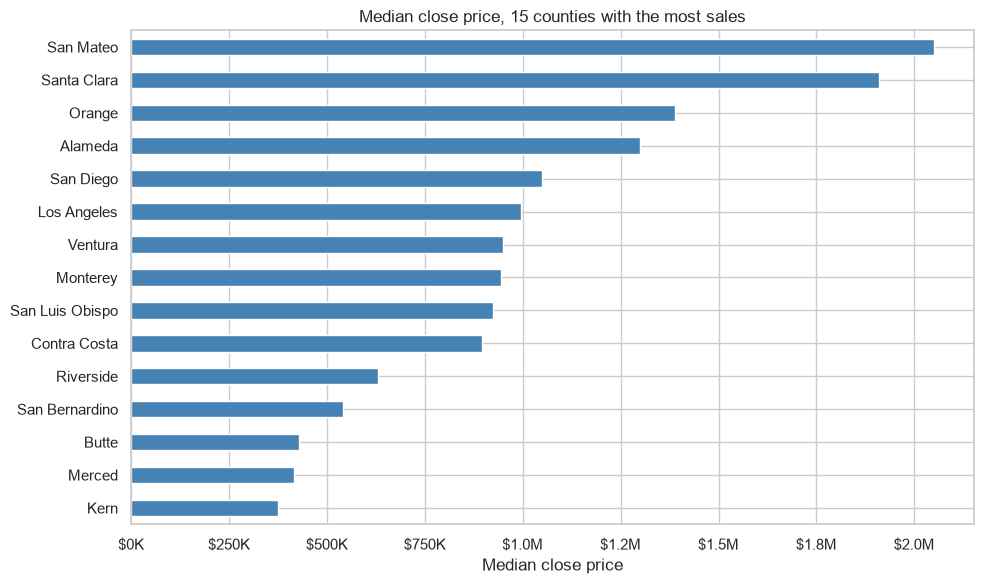

In [59]:
top_counties = county_stats.head(15).sort_values("median_price")

fig, ax = plt.subplots(figsize=(10, 6))
top_counties["median_price"].plot.barh(ax=ax, color="steelblue")
ax.xaxis.set_major_formatter(money_fmt)
ax.set(title="Median close price, 15 counties with the most sales", xlabel="Median close price", ylabel="")
plt.tight_layout()

Spread of price per sq ft within each county. If counties overlap a lot, location below the county level (city, zip, coordinates) matters.

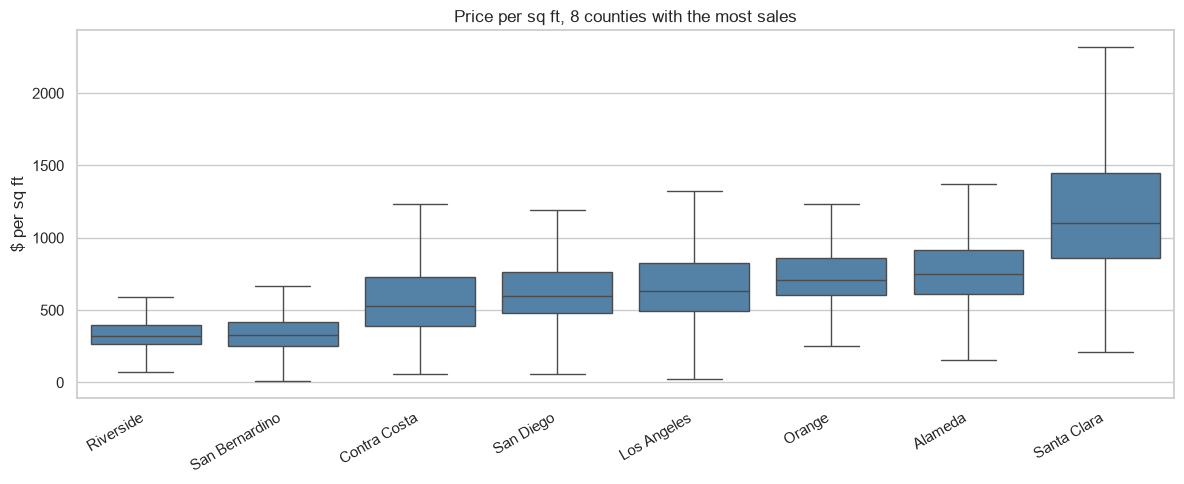

In [60]:
top8 = county_stats.head(8).index
subset = plot_df[plot_df["CountyOrParish"].isin(top8)]
order = subset.groupby("CountyOrParish")["PricePerSqft"].median().sort_values().index

fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=subset, x="CountyOrParish", y="PricePerSqft", order=order, showfliers=False, color="steelblue", ax=ax)
ax.set(title="Price per sq ft, 8 counties with the most sales", xlabel="", ylabel="$ per sq ft")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()

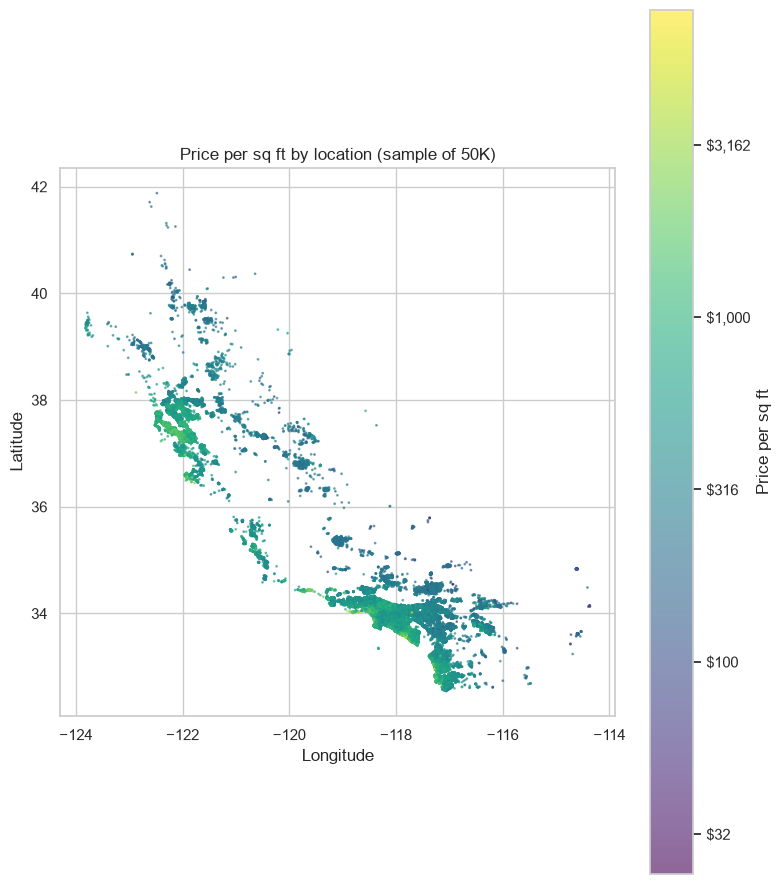

In [61]:
geo = plot_df[
    plot_df["Latitude"].between(32.4, 42.1) & plot_df["Longitude"].between(-124.5, -114.1)
].sample(min(50_000, len(plot_df)), random_state=42)

fig, ax = plt.subplots(figsize=(8, 9))
sc = ax.scatter(geo["Longitude"], geo["Latitude"], c=np.log10(geo["PricePerSqft"]), s=1, cmap="viridis", alpha=0.6)
cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("Price per sq ft")
cbar.ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"${10 ** v:,.0f}"))
ax.set(title="Price per sq ft by location (sample of 50K)", xlabel="Longitude", ylabel="Latitude", aspect="equal")
plt.tight_layout()

# Part 4: Hand off

## 4.2 Preprocessing decisions
Collected from the **Preprocessing** notes above. Rows marked TODO depend on the outputs in that section.

| # | Issue | Section | Proposed action |
|---|-------|---------|-----------------|
| 1 | `Unnamed: 0` is a leftover index from saving the monthly CSVs | 2.1 | Drop |
| 2 | Duplicate `ListingKey` rows from overlapping monthly exports | 2.1 | Drop duplicates, keep one row per `ListingKey` |
| 3 | Repeat sales of the same address | 2.1 | [TODO] |
| 4 | Columns that are empty or almost empty | 2.2, 2.4 | Drop the `empty` role columns |
| 5 | Missing core features (`LivingArea`, beds, baths, lot size, `YearBuilt`) | 2.2 | [TODO: drop rows or impute] |
| 6 | Zeros and extreme typos in `LivingArea`, beds, baths | 2.3 | [TODO: plausible ranges] |
| 7 | Three lot size columns, `LotSizeArea` has mixed units | 2.3 | [TODO: keep one] |
| 8 | Non-CA rows and bad coordinates | 2.3 | [TODO] |
| 9 | Leakage columns (`ListPrice`, `DaysOnMarket`, contract dates, office/agent fields) | 2.4 | Drop after using `ListPrice` for target checks |
| 10 | Agent names, emails, IDs | 2.4 | Drop |
| 11 | Extreme `ClosePrice` values and sale-to-list ratios | 3.1 | [TODO: thresholds] |
| 12 | Right-skewed `ClosePrice` | 3.1 | [TODO: model log price?] |
| 13 | Price drift over 28 months | 3.4 | Add sale date features, use a time-based train/test split |

## 4.3 Save filtered data
Scope filter only, with the date columns converted to datetimes. No cleaning. Requires `pyarrow` (`uv add pyarrow`).

In [64]:
OUT_PATH = "../data/intermediate/CRMLSSoldFiltered.parquet"
df.to_parquet(OUT_PATH, index=False)
print(f"Saved {len(df):,} rows x {df.shape[1]} columns to {OUT_PATH}")

ArrowKeyError: No type extension with name arrow.py_extension_type found